# 01 · Data Understanding: BMW i3 Battery and Heating Data in Real Driving Cycles

**Goal of this notebook:** understand the raw data before touching it. It loads every file, documents what is there
and records every quality issue. **Nothing is cleaned, renamed or dropped here**; that is step 02.

| | |
|---|---|
| Dataset | Battery and Heating Data in Real Driving Cycles (BMW i3, 60 Ah) |
| Original source | IEEE DataPort, Technical University of Munich |
| Mirror used | Kaggle `atechnohazard/battery-and-heating-data-in-real-driving-cycles` |
| Licence | CC BY 4.0 |

**Outputs**
- `reports/01_trip_inventory.csv`: one row per trip
- `reports/01_signal_dictionary.csv`: one row per signal, with unit, group and coverage
- `reports/01_quality_issues.csv`: every issue found, with the handling planned for step 02

In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DOWNLOAD = ROOT / "data" / "download"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

issues = []  # every quality issue found below is appended here


def add_issue(issue, scope, detail, severity, step02_handling):
    issues.append(dict(issue=issue, scope=scope, detail=detail, severity=severity, step02_handling=step02_handling))

## 1 · Provenance and file inventory

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


zip_path = next(DOWNLOAD.glob("*.zip"))
print(f"Original download : {zip_path.name}")
print(f"SHA-256           : {sha256(zip_path)}")

files = pd.DataFrame(
    [{"file": p.name, "type": p.suffix.lower(), "size_mb": round(p.stat().st_size / 1e6, 2)} for p in sorted(RAW.iterdir())]
)
files.groupby("type").agg(files=("file", "size"), size_mb=("size_mb", "sum")).round(1)

Original download : battery-and-heating-data-in-real-driving-cycles.zip


SHA-256           : fb59fa697344794321319c7e9d73968d563ee78500f2b173d445f78ff3cc40f5


,files,size_mb
type,,
.csv,70,199.2
.m,1,0.0
.xlsx,1,0.0


In [3]:
trip_files = sorted(RAW.glob("Trip*.csv"))
trip_ids = [p.stem for p in trip_files]
series = pd.Series([t[4] for t in trip_ids]).value_counts().sort_index()
print(f"Trip files: {len(trip_files)}  ->  " + ", ".join(f"series {k}: {v}" for k, v in series.items()))

claimed = 72
if len(trip_files) != claimed:
    add_issue("Trip count differs from dataset description", "dataset",
              f"description says {claimed} trips, {len(trip_files)} trip files are present",
              "low", "report the real count; use the files that exist")

Trip files: 70  ->  series A: 32, series B: 38


## 2 · Trip metadata: `Overview.xlsx`

The overview sheet holds one row per trip: date, route, weather, start/end temperatures and SoC, distance and duration.

In [4]:
ov_raw = pd.read_excel(RAW / "Overview.xlsx", header=0)
print("raw shape:", ov_raw.shape)
print("unnamed / empty header columns:", [c for c in ov_raw.columns if str(c).startswith("Unnamed")])
ov = ov_raw.dropna(how="all")
print("fully empty rows dropped for viewing:", len(ov_raw) - len(ov))
ov.head(3)

raw shape: (72, 16)
unnamed / empty header columns: ['Unnamed: 8', 'Unnamed: 13']
fully empty rows dropped for viewing: 2


,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,0.863,0.803,0.060,25.5,23.0,7.427690,16.82,NaN,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,0.803,0.673,0.130,32.0,23.0,23.509709,23.55,NaN,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,0.835,0.751,0.084,21.5,27.0,12.820846,11.18,NaN,"Automatic, Level 1",Target Cabin Temperature changed


In [5]:
unnamed = [c for c in ov_raw.columns if str(c).startswith("Unnamed")]
for c in unnamed:
    filled = ov[c].notna().sum()
    print(f"{c!r}: {filled} non-empty values, sample: {ov[c].dropna().head(3).tolist()}")

# An unlabelled column whose values match start SoC minus end SoC would be the SoC used per trip
soc_cols = [c for c in ov.columns if "State of Charge" in str(c)]
for c in unnamed:
    vals = pd.to_numeric(ov[c], errors="coerce")
    if vals.notna().sum() and len(soc_cols) == 2:
        diff = (ov[soc_cols[0]] - ov[soc_cols[1]]).round(3)
        share = (vals.round(3) == diff).mean()
        print(f"{c!r} equals start SoC - end SoC in {share:.0%} of rows")
        add_issue("Unlabelled column in Overview.xlsx", "Overview.xlsx",
                  f"{c!r} has no header; it matches start SoC minus end SoC in {share:.0%} of rows",
                  "low", "name it soc_used if the match holds, otherwise drop")

'Unnamed: 8': 70 non-empty values, sample: [0.05999999999999994, 0.13, 0.08399999999999996]
'Unnamed: 13': 0 non-empty values, sample: []
'Unnamed: 8' equals start SoC - end SoC in 99% of rows


In [6]:
date_col = ov.columns[1]
formats = ov[date_col].astype(str).str.replace(r"\d", "9", regex=True).value_counts()
print("date string patterns:")
print(formats.to_string())
if len(formats) > 1:
    add_issue("Inconsistent date formats", "Overview.xlsx",
              "dates use both 'YYYY-MM-DD_hh-mm-ss' and 'YYYY_MM_DD_hh-mm-ss'", "low",
              "parse both patterns into one datetime")

dup_start = ov[ov.duplicated(date_col, keep=False)][[ov.columns[0], date_col]]
if len(dup_start):
    print("\ntrips sharing the same start timestamp:")
    print(dup_start.to_string(index=False))
    add_issue("Duplicate trip start timestamps", "Overview.xlsx",
              ", ".join(dup_start[ov.columns[0]]) + " have identical start times", "low",
              "keep both trips; do not use start time as a unique key")

date string patterns:
Date
9999-99-99_99-99-99    66
9999_99_99_99-99-99     4

trips sharing the same start timestamp:
   Trip                Date
TripA30 2019-07-19_09-34-23
TripA31 2019-07-19_09-34-23


In [7]:
meta = ov.rename(columns={ov.columns[0]: "trip"})
meta["series"] = meta["trip"].str[4]
print(meta.groupby("series").agg(trips=("trip", "size")).to_string())
for col in ["Route/Area", "Weather"]:
    print(f"\n{col}:")
    print(meta.groupby(["series", col]).size().unstack(0, fill_value=0).to_string())

        trips
series       
A          32
B          38

Route/Area:
series                         A   B
Route/Area                          
FTMRoute                       0   7
FTMRoute (2x)                  0   1
FTMRoute reverse               0   1
Highway                        0   3
Munich East                   30   1
Munich North                   2  19
Munich North + Fast Charging   0   1
Munich Northeast               0   2
Munich South                   0   3

Weather:
series               A   B
Weather                   
cloudy               0  13
dark                 0   4
dark, little rainy   0   1
rainy                2   0
slightly cloudy     10  10
sunny               20   6
sunrise              0   3
sunset               0   1


## 3 · Raw file format

Checked by inspecting the bytes of the files:
- separator `;`, decimal point `.`
- encoding **Latin-1** (the degree sign `°` is byte `0xB0`), Windows line endings
- first column `Time [s]`, units in square brackets in the header

The reader below changes nothing except stripping whitespace around header names.

In [8]:
def read_trip(path):
    df = pd.read_csv(path, sep=";", encoding="latin-1")
    df.columns = [c.strip() for c in df.columns]
    return df


def raw_header(path):
    with open(path, encoding="latin-1") as f:
        return [c.strip() for c in f.readline().rstrip("\r\n").split(";")]


trips = {p.stem: read_trip(p) for p in trip_files}
headers = {p.stem: raw_header(p) for p in trip_files}
print(f"loaded {len(trips)} trips, {sum(len(d) for d in trips.values()):,} rows in total")

loaded 70 trips, 1,094,793 rows in total


## 4 · Per-trip inventory

In [9]:
def soc_col(df):
    return "SoC [%]" if "SoC [%]" in df.columns else None


rows = []
for t, df in trips.items():
    time = df.iloc[:, 0].to_numpy()
    dt = np.diff(time)
    soc = df[soc_col(df)] if soc_col(df) else pd.Series(dtype=float)
    rows.append(dict(
        trip=t, series=t[4], rows=len(df), columns=df.shape[1],
        duration_min=round(time[-1] / 60, 1),
        dt_median_s=round(float(np.median(dt)), 3), dt_min_s=round(float(dt.min()), 3), dt_max_s=round(float(dt.max()), 3),
        time_increasing=bool((dt > 0).all()),
        soc_start=soc.dropna().iloc[0] if soc.notna().any() else np.nan,
        soc_end=soc.dropna().iloc[-1] if soc.notna().any() else np.nan,
        missing_cells_pct=round(df.isna().to_numpy().mean() * 100, 2),
    ))
inventory = pd.DataFrame(rows)
inventory.to_csv(REPORTS / "01_trip_inventory.csv", index=False)

print(f"trips: {len(inventory)} | rows: {inventory.rows.sum():,} | driving time: {inventory.duration_min.sum() / 60:.1f} h")
print("sampling interval (median of medians):", inventory.dt_median_s.median(), "s")
print("all trips strictly increasing in time:", inventory.time_increasing.all())
inventory.groupby("series").agg(
    trips=("trip", "size"), rows=("rows", "sum"), hours=("duration_min", lambda s: round(s.sum() / 60, 1)),
    min_trip_min=("duration_min", "min"), max_trip_min=("duration_min", "max"),
)

trips: 70 | rows: 1,094,793 | driving time: 30.4 h
sampling interval (median of medians): 0.1 s
all trips strictly increasing in time: True


,trips,rows,hours,min_trip_min,max_trip_min
series,,,,,
A,32,467701,13.0,6.9,52.7
B,38,627092,17.4,5.9,93.5


In [10]:
irregular = inventory[(inventory.dt_min_s != inventory.dt_median_s) | (inventory.dt_max_s != inventory.dt_median_s)]
print("trips with any sampling interval other than the median:", len(irregular))
if len(irregular):
    print(irregular[["trip", "dt_median_s", "dt_min_s", "dt_max_s"]].to_string(index=False))
    add_issue("Irregular sampling", ", ".join(irregular.trip), "some time steps differ from the 10 Hz median",
              "medium", "resample onto a fixed time grid")

trips with any sampling interval other than the median: 0


## 5 · Schema per trip type

Summer trips (series A) and winter trips (series B) were recorded with different signal sets.

In [11]:
schema_groups = {}
for t, cols in headers.items():
    schema_groups.setdefault(tuple(cols), []).append(t)

schema_table = pd.DataFrame(
    [{"schema": f"S{i + 1}", "columns": len(cols), "trips": len(ts), "first": ts[0], "last": ts[-1]}
     for i, (cols, ts) in enumerate(sorted(schema_groups.items(), key=lambda kv: -len(kv[1])))]
)
schema_table

,schema,columns,trips,first,last
0,S1,48,37,TripB01,TripB37
1,S2,23,18,TripA03,TripA22
2,S3,28,12,TripA01,TripA32
3,S4,24,1,TripA11,TripA11
4,S5,22,1,TripA21,TripA21
5,S6,48,1,TripB38,TripB38


In [12]:
all_cols = sorted({c for cols in headers.values() for c in cols}, key=lambda c: min(
    cols.index(c) for cols in headers.values() if c in cols))
presence = pd.DataFrame({t: [c in cols for c in all_cols] for t, cols in headers.items()}, index=all_cols)
coverage = pd.DataFrame({
    "in_A_trips": presence[[t for t in presence.columns if t[4] == "A"]].sum(axis=1),
    "in_B_trips": presence[[t for t in presence.columns if t[4] == "B"]].sum(axis=1),
})
n_a, n_b = series["A"], series["B"]
common = coverage[(coverage.in_A_trips == n_a) & (coverage.in_B_trips == n_b)].index.tolist()
print(f"signals present in every trip ({len(common)}):")
print("  " + "\n  ".join(common))
print(f"\nsignals present in some trips only: {len(coverage) - len(common)}")
coverage[~coverage.index.isin(common)]

signals present in every trip (21):
  Time [s]
  Elevation [m]
  Throttle [%]
  Motor Torque [Nm]
  Longitudinal Acceleration [m/s^2]
  Regenerative Braking Signal
  Battery Voltage [V]
  Battery Current [A]
  Battery Temperature [°C]
  max. Battery Temperature [°C]
  SoC [%]
  displayed SoC [%]
  min. SoC [%]
  max. SoC [%)
  Heating Power CAN [kW]
  Requested Heating Power [W]
  AirCon Power [kW]
  Heater Signal
  Ambient Temperature [°C]
  Heat Exchanger Temperature [°C]
  Cabin Temperature Sensor [°C]

signals present in some trips only: 28


,in_A_trips,in_B_trips
Velocity [km/h],32,37
Velocity [km/h]]],0,1
Heating Power LIN [W],12,38
Heater Voltage [V],12,38
Requested Coolant Temperature [°C],31,38
Heater Current [A],12,38
,1,0
Coolant Temperature Heatercore [°C],12,38
Ambient Temperature Sensor [°C],0,38
Coolant Temperature Inlet [°C],12,38


In [13]:
UNIT = re.compile(r"^(?P<name>.*?)\s*\[(?P<unit>[^\]\)]*)[\]\)]+\s*$")
GROUPS = [
    ("battery", ["Battery", "SoC"]),
    ("heating & climate", ["Heat", "Heater", "Coolant", "AirCon", "Requested"]),
    ("cabin temperatures", ["Defrost", "Footweel", "Feetvent", "Head ", "Vent ", "Cabin"]),
    ("environment", ["Ambient", "Elevation"]),
    ("driving", ["Velocity", "Throttle", "Torque", "Acceleration", "Regenerative"]),
    ("time", ["Time"]),
]


def group_of(name):
    if not name:
        return "(empty header)"
    for g, keys in GROUPS:
        if any(k in name for k in keys):
            return g
    return "other"


dictionary = []
for c in all_cols:
    m = UNIT.match(c)
    name, unit = (m["name"], m["unit"]) if m else (c, "")
    dictionary.append(dict(raw_header=c, signal=name, unit=unit or "(none)", group=group_of(name),
                           in_A_trips=int(coverage.loc[c, "in_A_trips"]), in_B_trips=int(coverage.loc[c, "in_B_trips"])))
dictionary = pd.DataFrame(dictionary)
dictionary.to_csv(REPORTS / "01_signal_dictionary.csv", index=False)
print(dictionary.groupby("group").size().to_string())
dictionary

group
(empty header)         1
battery                8
cabin temperatures    15
driving                6
environment            3
heating & climate     15
time                   1


,raw_header,signal,unit,group,in_A_trips,in_B_trips
0,Time [s],Time,s,time,32,38
1,Velocity [km/h],Velocity,km/h,driving,32,37
2,Velocity [km/h]]],Velocity,km/h,driving,0,1
3,Elevation [m],Elevation,m,environment,32,38
4,Throttle [%],Throttle,%,driving,32,38
5,Motor Torque [Nm],Motor Torque,Nm,driving,32,38
6,Longitudinal Acceleration [m/s^2],Longitudinal Acceleration,m/s^2,driving,32,38
7,Regenerative Braking Signal,Regenerative Braking Signal,(none),driving,32,38
8,Battery Voltage [V],Battery Voltage,V,battery,32,38
9,Battery Current [A],Battery Current,A,battery,32,38


## 6 · Quality issues

Each check below records what it finds in the `issues` table. The *step02_handling* column is a plan only;
nothing is changed in this notebook.

### 6.1 Header problems

In [14]:
header_findings = []
for t, cols in headers.items():
    for c in cols:
        if c == "":
            header_findings.append((t, "empty header name (trailing separator)", c))
        if re.search(r"\]\]|\[[^\]]*\)$", c):
            header_findings.append((t, "malformed unit bracket", c))
    dups = sorted({c for c in cols if cols.count(c) > 1 and c})
    for c in dups:
        header_findings.append((t, "duplicate column name", c))

hf = pd.DataFrame(header_findings, columns=["trip", "problem", "header"])
summary = hf.groupby(["problem", "header"]).trip.agg(trips="size", examples=lambda s: ", ".join(s.head(3)))
print(summary.to_string())

for (problem, header), r in summary.iterrows():
    add_issue(f"Header: {problem}", f"{r.trips} trips (e.g. {r.examples})", repr(header), "low",
              "map every raw header to one clean snake_case name")

                                                                    trips                   examples
problem                                header                                                       
duplicate column name                  Temperature Vent right [°C]     38  TripB01, TripB02, TripB03
empty header name (trailing separator)                                  1                    TripA11
malformed unit bracket                 Velocity [km/h]]]                1                    TripB38
                                       max. SoC [%)                    70  TripA01, TripA02, TripA03


### 6.2 Missing values

In [15]:
KEY = ["Velocity [km/h]", "Battery Voltage [V]", "Battery Current [A]", "Battery Temperature [°C]", "SoC [%]",
       "Ambient Temperature [°C]", "Heating Power CAN [kW]"]

missing = pd.DataFrame({t: {k: (df[k].isna().mean() * 100 if k in df.columns else np.nan) for k in KEY}
                        for t, df in trips.items()}).T.round(1)
with_gaps = missing[(missing.fillna(0) > 0).any(axis=1)]
print("trips with missing values in key signals:")
print(with_gaps.to_string())

for t, r in with_gaps.iterrows():
    gaps = {k: v for k, v in r.items() if v and v > 0}
    add_issue("Missing values in key signals", t, ", ".join(f"{k} {v}%" for k, v in gaps.items()),
              "high" if max(gaps.values()) >= 10 else "medium",
              "interpolate short gaps only; flag long gaps and exclude them from SoC modelling")

all_nan_cols = [(t, c) for t, df in trips.items() for i, c in enumerate(df.columns) if df.iloc[:, i].isna().all()]
print("\ncolumns that are entirely empty:", all_nan_cols)
for t, c in all_nan_cols:
    add_issue("Column entirely empty", t, repr(c), "low", "drop for this trip")

trips with missing values in key signals:
         Velocity [km/h]  Battery Voltage [V]  Battery Current [A]  Battery Temperature [°C]  SoC [%]  Ambient Temperature [°C]  Heating Power CAN [kW]
TripB07              0.0                  0.0                  0.0                       0.0     18.2                       0.0                     0.0
TripB09              0.0                  0.0                  0.0                       0.0     36.6                       0.0                     0.0
TripB13              0.0                  0.0                  0.0                       0.0      0.4                       0.0                     0.0
TripB28              0.0                  0.0                  0.0                       0.0     11.9                       0.0                     0.0
TripB34              0.0                  0.0                  0.0                       0.0     60.1                       0.0                     0.0



columns that are entirely empty: [('TripB05', 'Coolant Volume Flow +500 [l/h]'), ('TripB06', 'Coolant Volume Flow +500 [l/h]')]


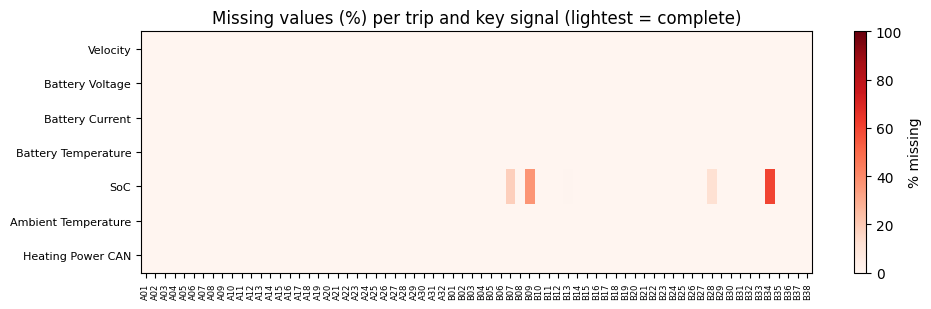

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(missing.fillna(-1).T.to_numpy(), aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_yticks(range(len(KEY)), [k.split(" [")[0] for k in KEY], fontsize=8)
ax.set_xticks(range(len(missing)), missing.index.str.replace("Trip", ""), rotation=90, fontsize=6)
ax.set_title("Missing values (%) per trip and key signal (lightest = complete)")
fig.colorbar(im, ax=ax, label="% missing")
fig.tight_layout()
fig.savefig(FIGURES / "01_missing_values.png", dpi=150)
plt.show()

### 6.3 Physically implausible values and glitches

In [17]:
LIMITS = {  # broad physical limits for a BMW i3 60 Ah pack and normal road driving
    "Battery Voltage [V]": (250, 420),
    "Battery Current [A]": (-500, 250),
    "Battery Temperature [°C]": (-30, 60),
    "SoC [%]": (1, 100),
    "Velocity [km/h]": (0, 160),
    "Ambient Temperature [°C]": (-30, 45),
}
out_of_range = []
for t, df in trips.items():
    for col, (lo, hi) in LIMITS.items():
        if col in df.columns:
            bad = df[col][(df[col] < lo) | (df[col] > hi)]
            if len(bad):
                out_of_range.append(dict(trip=t, signal=col, rows=len(bad), values=[float(v) for v in sorted(bad.unique())[:5]],
                                         positions=f"{bad.index.min()}..{bad.index.max()} of {len(df)}"))
oor = pd.DataFrame(out_of_range)
print(oor.to_string(index=False) if len(oor) else "no values outside the broad limits")
for r in oor.itertuples():
    add_issue("Value outside physical limits", r.trip, f"{r.signal}: {r.rows} rows {r.values} at rows {r.positions}",
              "medium", "set to missing, then treat as a gap")

   trip  signal  rows values             positions
TripB14 SoC [%]     1  [0.0] 38219..38219 of 38220


In [18]:
jumps = []
for t, df in trips.items():
    if "SoC [%]" in df.columns:
        step = df["SoC [%]"].diff().abs()
        big = step[step > 1.0]  # more than 1 percentage point in 0.1 s is not physical
        if len(big):
            jumps.append(dict(trip=t, jumps=len(big), largest=round(big.max(), 1)))
jumps = pd.DataFrame(jumps)
print(jumps.to_string(index=False) if len(jumps) else "no SoC jumps above 1 point per sample")
for r in jumps.itertuples():
    add_issue("SoC jump between consecutive samples", r.trip, f"{r.jumps} jumps, largest {r.largest} points",
              "medium", "check if caused by gaps; otherwise treat as glitch")

   trip  jumps  largest
TripB14      1     34.6


In [19]:
lin = "Heating Power LIN [W]"
lin_max = pd.Series({t: df[lin].max() for t, df in trips.items() if lin in df.columns})
typical = lin_max.median()
spikes = lin_max[lin_max > 2 * typical]
print(f"typical maximum heating power (LIN): {typical:.0f} W")
print("trips whose maximum is more than twice that:", spikes.round(0).to_dict())
for t, v in spikes.items():
    n = int((trips[t][lin] > 2 * typical).sum())
    add_issue("Heating power spike", t, f"{lin} reaches {v:.0f} W ({n} rows above {2 * typical:.0f} W)",
              "medium", "inspect; likely a bus glitch, clip or set to missing")

typical maximum heating power (LIN): 6997 W
trips whose maximum is more than twice that: {'TripB02': 38871.0}


### 6.4 Signal definitions to keep in mind

In [20]:
# Current sign: compare current under strong throttle with current while the regen signal is active
pooled = pd.concat([df[["Throttle [%]", "Regenerative Braking Signal", "Battery Current [A]"]] for df in trips.values()])
accel = pooled[pooled["Throttle [%]"] > 20]["Battery Current [A]"].mean()
regen = pooled[pooled["Regenerative Braking Signal"] != 0]["Battery Current [A]"].mean()
print(f"mean current, throttle > 20 %       : {accel:7.1f} A")
print(f"mean current, regen braking active  : {regen:7.1f} A")
print("=> negative current = discharge (driving), positive = charging (regeneration)" if accel < 0 < regen else
      "=> sign convention unclear, check manually")
add_issue("Current sign convention", "all trips", f"discharge is negative (mean {accel:.0f} A under throttle), "
          f"regeneration positive (mean {regen:.0f} A)", "info", "keep as is; document it in the data card")

mean current, throttle > 20 %       :   -32.3 A
mean current, regen braking active  :    32.2 A
=> negative current = discharge (driving), positive = charging (regeneration)


In [21]:
soc_gap = pd.Series({t: (df["displayed SoC [%]"] - df["SoC [%]"]).median() for t, df in trips.items()
                     if {"SoC [%]", "displayed SoC [%]"} <= set(df.columns)})
print(f"displayed SoC minus true SoC: median {soc_gap.median():.1f} points (range {soc_gap.min():.1f} to {soc_gap.max():.1f})")
add_issue("Two different SoC signals", "all trips", f"displayed SoC is about {soc_gap.median():.0f} points above "
          "the true SoC (usable-window buffer)", "info", "model the true SoC; keep displayed SoC for comparison only")

displayed SoC minus true SoC: median 10.2 points (range -4.9 to 15.6)


In [22]:
temp = "Battery Temperature [°C]"
whole = pd.Series({t: (df[temp].dropna() % 1 == 0).mean() for t, df in trips.items()})
print("share of whole-degree battery temperature readings:")
print(whole.groupby(whole.index.str[4]).describe()[["min", "50%", "max"]].round(2).to_string())
add_issue("Coarse battery temperature", "all trips", f"battery temperature is logged in whole degrees "
          f"(at least {whole.min():.0%} of readings per trip; the rest are in-between values)", "info",
          "do not over-interpret small temperature changes")

share of whole-degree battery temperature readings:
    min  50%  max
A  0.99  1.0  1.0
B  0.99  1.0  1.0


In [23]:
# Charging while parked: speed zero and sustained positive current (regeneration needs motion)
charging = {}
for t, df in trips.items():
    v = df.filter(like="Velocity").iloc[:, 0]
    parked_charging = (v == 0) & (df["Battery Current [A]"] > 20)
    minutes = parked_charging.sum() * 0.1 / 60
    if minutes >= 1:
        charging[t] = round(float(minutes), 1)
print("trips with at least 1 minute of charging while parked (minutes):", charging)
if charging:
    add_issue("Trips contain charging phases", ", ".join(charging),
              "speed is zero while current is strongly positive: the car was charged during the recording",
              "medium", "label driving / charging / idle phases; analyse charging separately from driving")

trips with at least 1 minute of charging while parked (minutes):

 {'TripB04': 23.5, 'TripB09': 42.1}


### 6.5 Overview sheet vs the trip files

In [24]:
check = meta.set_index("trip").join(inventory.drop(columns="series").set_index("trip"), how="outer")
dur_col = [c for c in meta.columns if str(c).startswith("Duration")][0]
soc_start_col = soc_cols[0]
check["duration_diff_min"] = (check[dur_col] - check["duration_min"]).round(1)
check["soc_start_diff"] = (check[soc_start_col] * 100 - check["soc_start"]).round(1)
mismatch = check[(check.duration_diff_min.abs() > 1) | (check.soc_start_diff.abs() > 1)]
print(f"trips in overview: {meta.trip.nunique()} | trips with files: {len(inventory)}")
print("missing on either side:", sorted(set(meta.trip) ^ set(inventory.trip)) or "none")
print("\ntrips where overview and file disagree by more than 1 minute or 1 SoC point:")
print(mismatch[["duration_min", dur_col, "duration_diff_min", "soc_start", soc_start_col, "soc_start_diff"]].to_string()
      if len(mismatch) else "none")
for t, r in mismatch.iterrows():
    add_issue("Overview disagrees with trip file", t,
              f"duration diff {r.duration_diff_min} min, start SoC diff {r.soc_start_diff} points", "low",
              "trust the trip file; keep the overview value for reference")

trips in overview: 70 | trips with files: 70
missing on either side: none

trips where overview and file disagree by more than 1 minute or 1 SoC point:
none


## 7 · First look: one summer and one winter trip

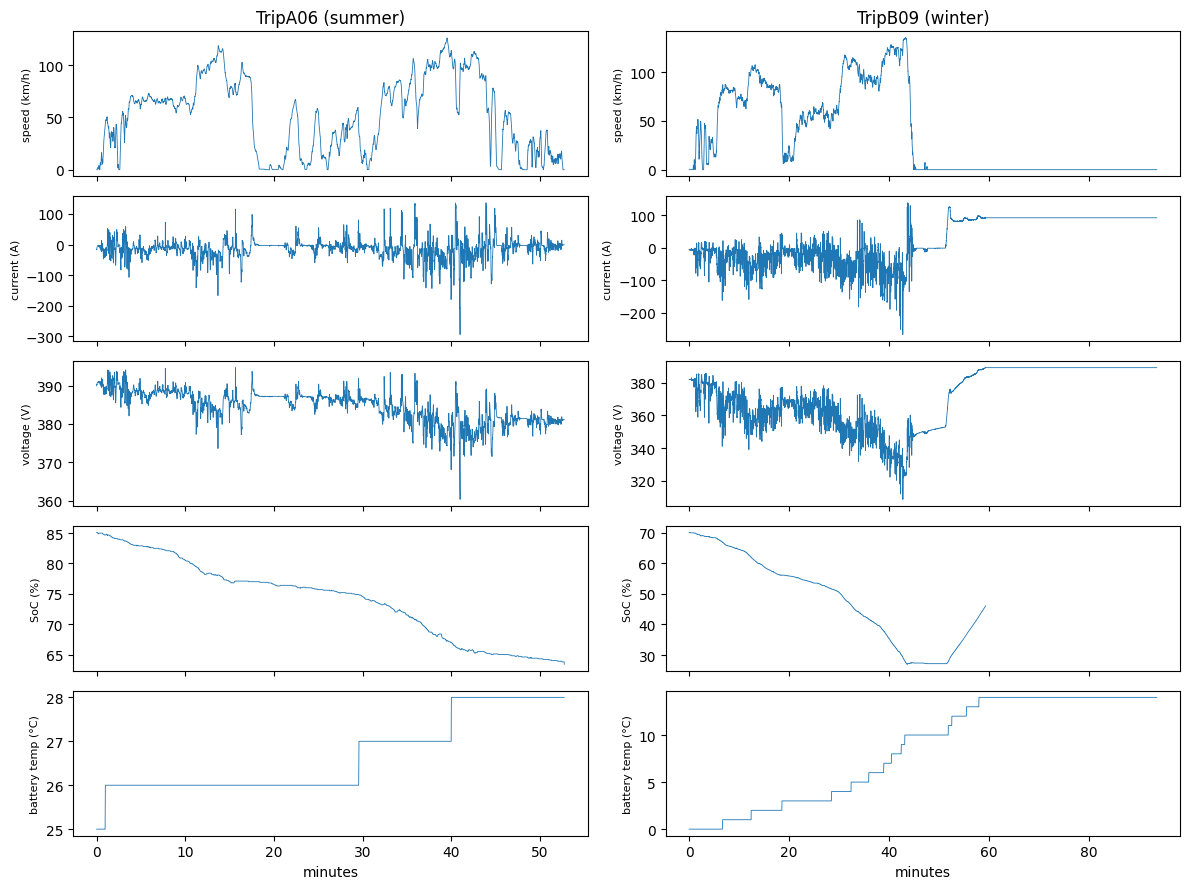

In [25]:
pair = ["TripA06", "TripB09"]
signals = [("Velocity [km/h]", "speed (km/h)"), ("Battery Current [A]", "current (A)"),
           ("Battery Voltage [V]", "voltage (V)"), ("SoC [%]", "SoC (%)"), ("Battery Temperature [°C]", "battery temp (°C)")]
fig, axes = plt.subplots(len(signals), 2, figsize=(12, 9), sharex="col")
for j, t in enumerate(pair):
    df = trips[t]
    minutes = df["Time [s]"] / 60
    for i, (col, label) in enumerate(signals):
        axes[i, j].plot(minutes, df[col], lw=0.6)
        axes[i, j].set_ylabel(label, fontsize=8)
    axes[0, j].set_title(f"{t} ({'summer' if t[4] == 'A' else 'winter'})")
    axes[-1, j].set_xlabel("minutes")
fig.tight_layout()
fig.savefig(FIGURES / "01_summer_vs_winter_trip.png", dpi=150)
plt.show()

## 8 · Issue register

In [26]:
issue_table = pd.DataFrame(issues)
order = {"high": 0, "medium": 1, "low": 2, "info": 3}
issue_table = issue_table.sort_values("severity", key=lambda s: s.map(order)).reset_index(drop=True)
issue_table.to_csv(REPORTS / "01_quality_issues.csv", index=False)
print(issue_table.severity.value_counts().reindex(order).dropna().astype(int).to_string())
issue_table

severity
high       4
medium     5
low       10
info       3


,issue,scope,detail,severity,step02_handling
0,Missing values in key signals,TripB34,SoC [%] 60.1%,high,interpolate short gaps only; flag long gaps and exclude them from SoC modelling
1,Missing values in key signals,TripB28,SoC [%] 11.9%,high,interpolate short gaps only; flag long gaps and exclude them from SoC modelling
2,Missing values in key signals,TripB09,SoC [%] 36.6%,high,interpolate short gaps only; flag long gaps and exclude them from SoC modelling
3,Missing values in key signals,TripB07,SoC [%] 18.2%,high,interpolate short gaps only; flag long gaps and exclude them from SoC modelling
4,Value outside physical limits,TripB14,SoC [%]: 1 rows [0.0] at rows 38219..38219 of 38220,medium,"set to missing, then treat as a gap"
5,Missing values in key signals,TripB13,SoC [%] 0.4%,medium,interpolate short gaps only; flag long gaps and exclude them from SoC modelling
6,Heating power spike,TripB02,Heating Power LIN [W] reaches 38871 W (1273 rows above 13993 W),medium,"inspect; likely a bus glitch, clip or set to missing"
7,SoC jump between consecutive samples,TripB14,"1 jumps, largest 34.6 points",medium,check if caused by gaps; otherwise treat as glitch
8,Trips contain charging phases,"TripB04, TripB09",speed is zero while current is strongly positive: the car was charged during...,medium,label driving / charging / idle phases; analyse charging separately from dri...
9,Header: malformed unit bracket,"70 trips (e.g. TripA01, TripA02, TripA03)",'max. SoC [%)',low,map every raw header to one clean snake_case name


## 9 · What we now know

**The data**
- 70 trips (the description says 72): 32 summer trips (series A, Jun–Jul 2019) and 38 winter trips (series B, Dec 2019–Feb 2020) around Munich.
- About 1.09 million rows and 30 hours of driving, sampled at a steady 10 Hz with no time disorder.
- The core battery signals (voltage, current, temperature, true SoC), the driving signals and the heating power are present in every trip.
  Winter trips add detailed heating, coolant and cabin temperatures.
- Current sign: negative means discharge while driving, positive means regeneration or charging.
- The displayed SoC sits about 10 points above the true SoC. Battery temperature is logged in whole degrees.
- Two trips include charging while parked: B04 (labelled "Fast Charging" in the overview) and B09 (not labelled).

**What step 02 must handle** (see `reports/01_quality_issues.csv`)
1. One shared schema: map both summer and winter header sets to clean names, fixing the malformed and duplicated headers.
2. SoC gaps in B07, B09, B28 and B34, plus small ones in B13. Interpolate short gaps; flag long ones.
3. Glitches: the final SoC = 0 row in B14, and the heating-power spike in B02.
4. Phase labels: driving, charging and idle.
5. Overview sheet: parse both date formats, name the unlabelled SoC-used column, and remember that A30/A31 share a start time.